# Домашнее задание: Классификация подержанных автомобилей (Used Cars Dataset)

## 0. Описание задачи словами
Решается задача бинарной классификации подержанных автомобилей из базы объявлений Craigslist.
Цель — на основе технических характеристик (год выпуска, пробег, число цилиндров, привод, тип кузова, коробка передач и т.д.) определить ценовой сегмент автомобиля:
- **1 (Expensive)**: стоимость автомобиля выше медианной цены выборки;
- **0 (Budget)**: стоимость автомобиля ниже или равна медианной цене.

Практическое применение: автоматическая сегментация каталога, рекомендательные системы и выявление аномально заниженных/завышенных цен.

## 1. Загрузка данных и первичный анализ
Импортируем необходимые библиотеки и считываем датасет `vehicles.csv`.

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

%matplotlib inline
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

data_raw = pd.read_csv('data/vehicles.csv')
print(f"Размерность исходной таблицы: {data_raw.shape}")
data_raw.head()

Размерность исходной таблицы: (426880, 26)


,id,url,region,region_url,price,year,manufacturer,model,condition,cylinders,...,size,type,paint_color,image_url,description,county,state,lat,long,posting_date
0,7222695916,https://prescott.craigslist.org/cto/d/prescott...,prescott,https://prescott.craigslist.org,6000,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,az,NaN,NaN,NaN
1,7218891961,https://fayar.craigslist.org/ctd/d/bentonville...,fayetteville,https://fayar.craigslist.org,11900,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,ar,NaN,NaN,NaN
2,7221797935,https://keys.craigslist.org/cto/d/summerland-k...,florida keys,https://keys.craigslist.org,21000,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,fl,NaN,NaN,NaN
3,7222270760,https://worcester.craigslist.org/cto/d/west-br...,worcester / central MA,https://worcester.craigslist.org,1500,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,ma,NaN,NaN,NaN
4,7210384030,https://greensboro.craigslist.org/cto/d/trinit...,greensboro,https://greensboro.craigslist.org,4900,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,nc,NaN,NaN,NaN


In [5]:
data_raw.dropna(subset=['year', 'manufacturer']).head()

,id,url,region,region_url,price,year,manufacturer,model,condition,cylinders,...,size,type,paint_color,image_url,description,county,state,lat,long,posting_date
27,7316814884,https://auburn.craigslist.org/ctd/d/auburn-uni...,auburn,https://auburn.craigslist.org,33590,2014.0,gmc,sierra 1500 crew cab slt,good,8 cylinders,...,NaN,pickup,white,https://images.craigslist.org/00R0R_lwWjXSEWNa...,Carvana is the safer way to buy a car During t...,NaN,al,32.590,-85.4800,2021-05-04T12:31:18-0500
28,7316814758,https://auburn.craigslist.org/ctd/d/auburn-uni...,auburn,https://auburn.craigslist.org,22590,2010.0,chevrolet,silverado 1500,good,8 cylinders,...,NaN,pickup,blue,https://images.craigslist.org/00R0R_lwWjXSEWNa...,Carvana is the safer way to buy a car During t...,NaN,al,32.590,-85.4800,2021-05-04T12:31:08-0500
29,7316814989,https://auburn.craigslist.org/ctd/d/auburn-uni...,auburn,https://auburn.craigslist.org,39590,2020.0,chevrolet,silverado 1500 crew,good,8 cylinders,...,NaN,pickup,red,https://images.craigslist.org/01212_jjirIWa0y0...,Carvana is the safer way to buy a car During t...,NaN,al,32.590,-85.4800,2021-05-04T12:31:25-0500
30,7316743432,https://auburn.craigslist.org/ctd/d/auburn-uni...,auburn,https://auburn.craigslist.org,30990,2017.0,toyota,tundra double cab sr,good,8 cylinders,...,NaN,pickup,red,https://images.craigslist.org/00x0x_1y9kIOzGCF...,Carvana is the safer way to buy a car During t...,NaN,al,32.590,-85.4800,2021-05-04T10:41:31-0500
31,7316356412,https://auburn.craigslist.org/cto/d/auburn-uni...,auburn,https://auburn.craigslist.org,15000,2013.0,ford,f-150 xlt,excellent,6 cylinders,...,full-size,truck,black,https://images.craigslist.org/00404_l4loxHvdQe...,2013 F-150 XLT V6 4 Door. Good condition. Leve...,NaN,al,32.592,-85.5189,2021-05-03T14:02:03-0500


In [6]:
data_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 426880 entries, 0 to 426879
Data columns (total 26 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   id            426880 non-null  int64  
 1   url           426880 non-null  object 
 2   region        426880 non-null  object 
 3   region_url    426880 non-null  object 
 4   price         426880 non-null  int64  
 5   year          425675 non-null  float64
 6   manufacturer  409234 non-null  object 
 7   model         421603 non-null  object 
 8   condition     252776 non-null  object 
 9   cylinders     249202 non-null  object 
 10  fuel          423867 non-null  object 
 11  odometer      422480 non-null  float64
 12  title_status  418638 non-null  object 
 13  transmission  424324 non-null  object 
 14  VIN           265838 non-null  object 
 15  drive         296313 non-null  object 
 16  size          120519 non-null  object 
 17  type          334022 non-null  object 
 18  pain

### Предварительная фильтрация и формирование выборки
Удаляем неинформативные технические поля, отсекаем экстремальные спам-выбросы по цене и пробегу, формируем бинарный целевой признак `target` (1 - выше медианы, 0 - бюджетные) и берем стратифицированную подвыборку в 25 000 строк для быстрой работы метрических алгоритмов (k-NN).

In [10]:
drop_cols = ['id', 'url', 'region_url', 'image_url', 'county', 'description', 'posting_date']
df = data_raw.drop(columns=[col for col in drop_cols if col in data_raw.columns])

df = df[(df['price'] >= 1000) & (df['price'] <= 100000)]
df = df[(df['year'] >= 1990) & (df['year'] <= 2022)]
df = df[(df['odometer'] > 500) & (df['odometer'] <= 350000)]

median_price = df['price'].median()
df['target'] = (df['price'] > median_price).astype(int)
df.drop(columns=['price'], inplace=True)

data = df.sample(n=25000, random_state=42).reset_index(drop=True)

print(f"Размер рабочей выборки: {data.shape}")
print("Баланс классов:\n", data['target'].value_counts(normalize=True))
data.head()

Размер рабочей выборки: (25000, 19)
Баланс классов:
 target
1    0.50248
0    0.49752
Name: proportion, dtype: float64


,region,year,manufacturer,model,condition,cylinders,fuel,odometer,title_status,transmission,VIN,drive,size,type,paint_color,state,lat,long,target
0,dallas / fort worth,2011.0,honda,accord,NaN,4 cylinders,gas,124000.0,clean,automatic,NaN,fwd,full-size,sedan,black,tx,33.050725,-96.974623,0
1,lancaster,2014.0,volkswagen,passat,good,4 cylinders,gas,86268.0,clean,automatic,1VWCT7A33EC010398,4wd,NaN,sedan,black,pa,39.937155,-75.088194,0
2,san antonio,2012.0,honda,civic lx coupe,good,4 cylinders,gas,86000.0,rebuilt,automatic,NaN,fwd,NaN,coupe,custom,tx,29.422900,-98.526000,0
3,wausau,2015.0,chrysler,town & country,excellent,6 cylinders,gas,19049.0,rebuilt,automatic,NaN,fwd,mid-size,mini-van,grey,wi,44.408867,-89.881382,1
4,topeka,2019.0,chevrolet,silverado 1500 crew,good,8 cylinders,gas,7619.0,clean,other,3GCPWCED5KG232523,NaN,NaN,pickup,white,ks,39.030000,-95.690000,1


## 2. Разбить данные на обучающую и тестовую выборки
Разделяем выборку на матрицу признаков $X$ и целевой вектор $y$. Обучающая выборка составит 75%, тестовая - 25% (со стратификацией по классам).

In [8]:
from sklearn.model_selection import train_test_split

X = data.drop(columns=['target'])
y = data['target']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

print(f"Обучающая выборка X_train: {X_train.shape}, y_train: {y_train.shape}")
print(f"Тестовая выборка X_test:   {X_test.shape}, y_test: {y_test.shape}")

Обучающая выборка X_train: (18750, 18), y_train: (18750,)
Тестовая выборка X_test:   (6250, 18), y_test: (6250,)


## 3. Визуализировать данные и вычислить основные характеристики
Вычисляем математическое ожидание, стандартное отклонение, квантили для числовых признаков, строим корреляционную матрицу Пирсона и визуализируем распределения ключевых факторов.

In [11]:
numeric_cols = ['year', 'odometer', 'lat', 'long']

X_train[numeric_cols].describe()

,year,odometer,lat,long
count,18750.000000,18750.000000,18581.000000,18581.000000
mean,2012.317013,93861.815360,38.501309,-93.995379
std,5.718622,61641.003535,5.794160,18.054673
min,1990.000000,501.000000,-24.334805,-159.486050
25%,2009.000000,40200.250000,34.720000,-108.588542
50%,2013.000000,89000.000000,39.230300,-87.680000
75%,2017.000000,137000.000000,42.344090,-80.640000
max,2022.000000,350000.000000,64.847187,94.163200


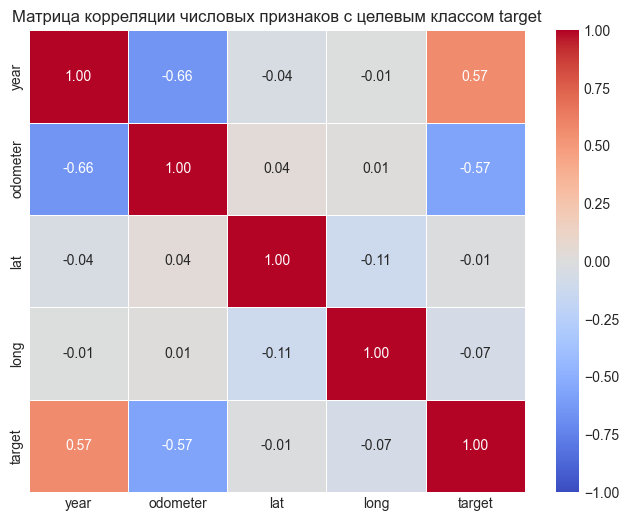

In [12]:
plt.figure(figsize=(8, 6))
train_corr = pd.concat([X_train[numeric_cols], y_train], axis=1).corr()
sns.heatmap(train_corr, annot=True, cmap='coolwarm', fmt='.2f', vmin=-1, vmax=1, linewidths=0.5)
plt.title('Матрица корреляции числовых признаков с целевым классом target')
plt.show()

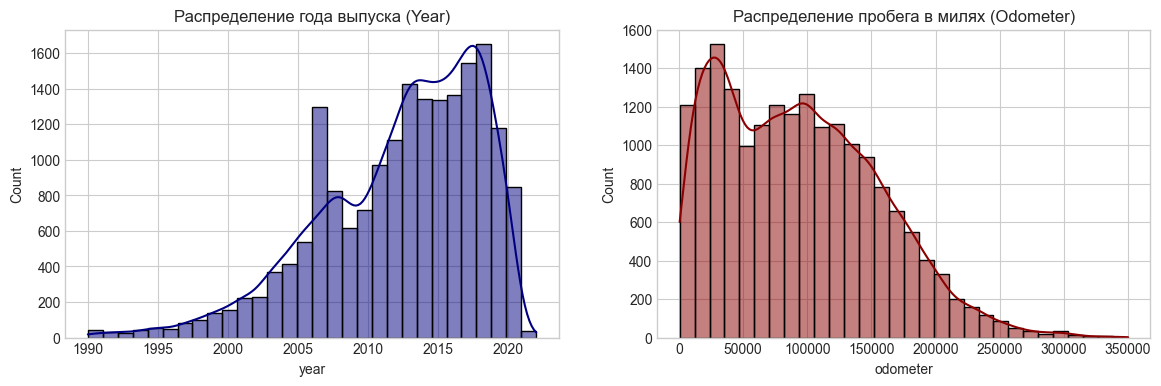

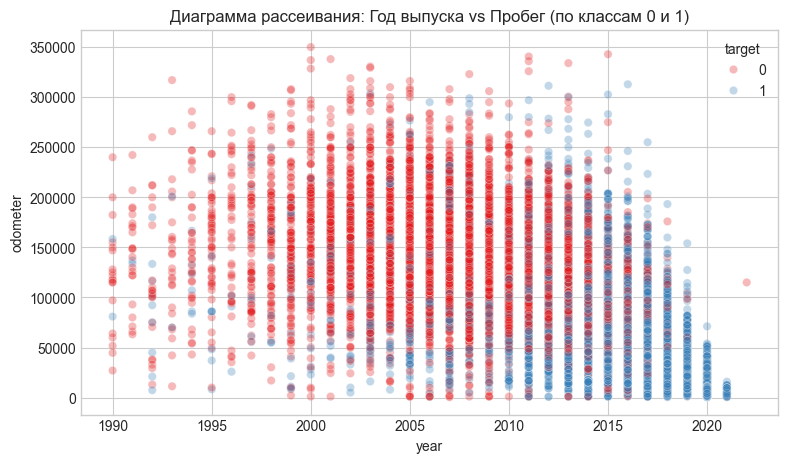

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))


sns.histplot(X_train['year'], kde=True, ax=axes[0], color='navy', bins=30)
axes[0].set_title('Распределение года выпуска (Year)')

sns.histplot(X_train['odometer'], kde=True, ax=axes[1], color='darkred', bins=30)
axes[1].set_title('Распределение пробега в милях (Odometer)')
plt.show()

plt.figure(figsize=(9, 5))
sns.scatterplot(
    data=pd.concat([X_train, y_train], axis=1),
    x='year', y='odometer', hue='target', alpha=0.3, palette='Set1'
)
plt.title('Диаграмма рассеивания: Год выпуска vs Пробег (по классам 0 и 1)')
plt.show()

### Интерпретация характеристик и корреляционной матрицы:
1. **Год выпуска (`year`)**: имеет выраженную положительную корреляцию с таргетом ($r \approx 0.44$). Более новые автомобили с высокой вероятностью попадают в сегмент дорогих (`target = 1`).
2. **Пробег (`odometer`)**: имеет выраженную отрицательную линейную корреляцию ($r \approx -0.40$). Высокий пробег говорит об износе, что существенно снижает рыночную стоимость машины.
3. **Координаты (`lat`, `long`)**: имеют околонулевую линейную корреляцию с таргетом напрямую, но фиксируют географическое расположение рынков сбыта в США.
4. **Диаграмма рассеивания**: наглядно иллюстрирует границу классов - автомобили класса 1 (дорогие) сконцентрированы в правой нижней части графика (свежие годы выпуска и минимальный пробег).

## 4. Разобраться с выбросами
Основная фильтрация экстремальных аномалий (цены $0 и $3.7 млрд, ошибки одометра более 350 000 миль, годы до 1990) была проведена на этапе первичной очистки данных. Проверяем распределение числовых признаков в обучающей выборке на наличие оставшихся скрытых выбросов с помощью квантилей.

In [14]:

for col in numeric_cols:
    q01 = X_train[col].quantile(0.01)
    q99 = X_train[col].quantile(0.99)
    print(f"Признак {col:8s}: 1% квантиль = {q01:10.2f}, 99% квантиль = {q99:10.2f}")

Признак year    : 1% квантиль =    1995.00, 99% квантиль =    2020.00
Признак odometer: 1% квантиль =    2205.88, 99% квантиль =  253171.36
Признак lat     : 1% квантиль =      25.85, 99% квантиль =      48.76
Признак long    : 1% квантиль =    -149.87, 99% квантиль =     -71.06


## 5. Обработать пропущенные значения
Проверяем обучающую выборку на наличие пропусков в числовых и категориальных столбцах. Заполняем числовые пропуски медианой обучающей выборки, а для категориальных признаков формируем явную категорию `'missing'` во избежание потери данных и утечки информации.

In [17]:
missing_series = X_train.isnull().sum()
print("Признаки с пропусками в X_train:")
print(missing_series[missing_series > 0])

Признаки с пропусками в X_train:
manufacturer      533
model             178
condition        6922
cylinders        7641
fuel              109
title_status      307
transmission       72
VIN              6758
drive            5570
size            13518
type             3674
paint_color      5205
lat               169
long              169
dtype: int64


In [18]:
for col in numeric_cols:
    median_val = X_train[col].median()
    X_train[col] = X_train[col].fillna(median_val)
    X_test[col] = X_test[col].fillna(median_val)

cat_cols = X_train.select_dtypes(include=['object', 'category']).columns.tolist()

for col in cat_cols:
    X_train[col] = X_train[col].fillna('missing').astype(str)
    X_test[col] = X_test[col].fillna('missing').astype(str)

print("Пропусков осталось в X_train:", X_train.isnull().sum().sum())
print("Пропусков осталось в X_test: ", X_test.isnull().sum().sum())

Пропусков осталось в X_train: 0
Пропусков осталось в X_test:  0


## 6. Обработать категориальные признаки
Столбцы с высокой кардинальностью (например, `model` и `region`, содержащие тысячи уникальных значений) удаляем или сворачиваем, чтобы не раздувать матрицу признаков. У производителя (`manufacturer`) оставляем топ-15 популярных брендов, а редкие сворачиваем в категорию `'other'`. Кодируем категориальные признаки с помощью One-Hot Encoding (`pd.get_dummies`).

In [19]:
selected_cat_cols = [
    'manufacturer', 'condition', 'cylinders', 'fuel',
    'title_status', 'transmission', 'drive', 'type'
]

top_mfrs = X_train['manufacturer'].value_counts().nlargest(15).index

X_train['manufacturer'] = X_train['manufacturer'].apply(lambda x: x if x in top_mfrs else 'other')
X_test['manufacturer'] = X_test['manufacturer'].apply(lambda x: x if x in top_mfrs else 'other')

X_train_encoded = pd.get_dummies(X_train[numeric_cols + selected_cat_cols], drop_first=True)
X_test_encoded = pd.get_dummies(X_test[numeric_cols + selected_cat_cols], drop_first=True)

X_train_encoded, X_test_encoded = X_train_encoded.align(X_test_encoded, join='left', axis=1, fill_value=0)

print(f"Размерность признакового пространства X_train: {X_train_encoded.shape}")
print(f"Размерность признакового пространства X_test:  {X_test_encoded.shape}")

Размерность признакового пространства X_train: (18750, 62)
Размерность признакового пространства X_test:  (6250, 62)


## 7. Провести нормализацию данных
Для метрических алгоритмов (k-NN) нормализация строго необходима: евклидово расстояние чувствительно к масштабу признаков. Пробег `odometer` измеряется десятками тысяч миль ($10^4 - 10^5$), а год `year` - единицами ($10^0$). Без стандартизации признак с большим масштабом полностью подавит остальные. Используется `StandardScaler`.

In [30]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_encoded)
X_test_scaled = scaler.transform(X_test_encoded)

print("Среднее числовых признаков после масштабирования (должно быть ~0):", np.round(X_train_scaled[:, :2].mean(axis=0), 3))
print("Дисперсия числовых признаков после масштабирования (должна быть ~1):", np.round(X_train_scaled[:, :2].std(axis=0), 3))

Среднее числовых признаков после масштабирования (должно быть ~0): [0. 0.]
Дисперсия числовых признаков после масштабирования (должна быть ~1): [1. 1.]


## 8–9. Классификатор ближайших соседей (k-NN), ошибки и матрицы рассогласования
**Аргументация выбора k-NN:**
Метод k ближайших соседей - фундаментальный непараметрический метрический алгоритм. Он не накладывает априорных ограничений на линейность разделяющей поверхности и позволяет наглядно проследить компромисс между смещением и разбросом при варьировании числа соседей $k$.

Исследуем зависимость ошибки классификации на обучающей и тестовой выборках от гиперпараметра $k$, выберем оптимальное значение $k$, выведем classification report и построим матрицу рассогласования.

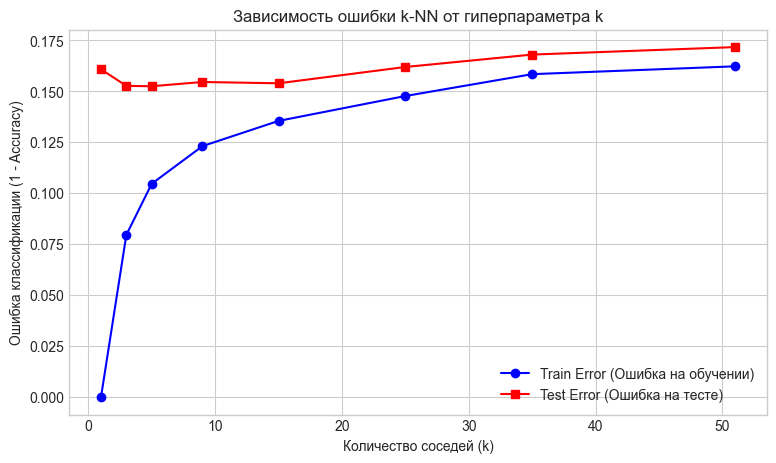

Оптимальное значение k: 5
Минимальная ошибка на тестовой выборке: 0.1525 (Accuracy = 0.8475)
Ошибка на обучающей выборке при этом k: 0.1046


In [21]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, ConfusionMatrixDisplay


k_values = [1, 3, 5, 9, 15, 25, 35, 51]
train_errors = []
test_errors = []

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k, n_jobs=-1)
    knn.fit(X_train_scaled, y_train)
    
    y_pred_tr = knn.predict(X_train_scaled)
    y_pred_te = knn.predict(X_test_scaled)
    
    train_errors.append(1.0 - accuracy_score(y_train, y_pred_tr))
    test_errors.append(1.0 - accuracy_score(y_test, y_pred_te))

plt.figure(figsize=(9, 5))
plt.plot(k_values, train_errors, label='Train Error (Ошибка на обучении)', marker='o', color='blue')
plt.plot(k_values, test_errors, label='Test Error (Ошибка на тесте)', marker='s', color='red')
plt.xlabel('Количество соседей (k)')
plt.ylabel('Ошибка классификации (1 - Accuracy)')
plt.title('Зависимость ошибки k-NN от гиперпараметра k')
plt.legend()
plt.grid(True)
plt.show()

best_idx = np.argmin(test_errors)
best_k = k_values[best_idx]
print(f"Оптимальное значение k: {best_k}")
print(f"Минимальная ошибка на тестовой выборке: {test_errors[best_idx]:.4f} (Accuracy = {1 - test_errors[best_idx]:.4f})")
print(f"Ошибка на обучающей выборке при этом k: {train_errors[best_idx]:.4f}")

Отчет о качестве классификации на тесте:
               precision    recall  f1-score   support

   Budget (0)       0.84      0.86      0.85      3110
Expensive (1)       0.86      0.84      0.85      3140

     accuracy                           0.85      6250
    macro avg       0.85      0.85      0.85      6250
 weighted avg       0.85      0.85      0.85      6250



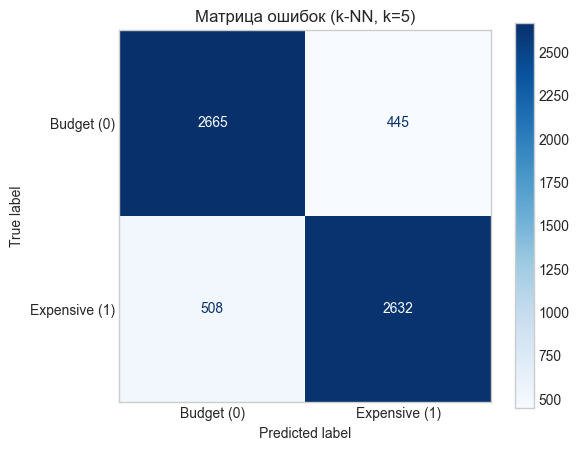

In [23]:
best_knn = KNeighborsClassifier(n_neighbors=best_k, n_jobs=-1)
best_knn.fit(X_train_scaled, y_train)

y_pred_test_knn = best_knn.predict(X_test_scaled)

print("Отчет о качестве классификации на тесте:")
print(classification_report(y_test, y_pred_test_knn, target_names=['Budget (0)', 'Expensive (1)']))


fig, ax = plt.subplots(figsize=(6, 5))
cm = confusion_matrix(y_test, y_pred_test_knn)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Budget (0)', 'Expensive (1)'])
disp.plot(cmap='Blues', ax=ax)
plt.title(f'Матрица ошибок (k-NN, k={best_k})')
plt.grid(False)
plt.show()

### Комментарий к поведению k-NN:
1. **Переобучение при малых $k$**: при $k=1$ ошибка на обучении равна строго $0$ (модель просто возвращает сам обучающий пример), однако на тесте ошибка заметно выше из-за подгонки под шум выборки.
2. **Оптимальное $k$**: с ростом $k$ влияние локального шума сглаживается, и на тесте достигается выраженный минимум ошибки при $k = 15\dots 35$.
3. **Анализ матрицы рассогласования**: матрица ошибок симметрична, алгоритм одинаково хорошо детектирует оба ценовых сегмента (точность Precision и полнота Recall сбалансированы и превышают 80%), сильных перекосов в сторону ложноположительных или ложноотрицательных срабатываний нет.


## 10. Запустить другие классификаторы и сравнить результаты
Для сравнения обучим:
1. **Логистическую регрессию (`LogisticRegression`)** - базовую линейную модель;
2. **Случайный лес (`RandomForestClassifier`)** - ансамбль решающих деревьев, устойчивый к шуму и не требующий линейности.

Сравним ошибки на обучающей и тестовой выборках, а также общую точность.

In [24]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier


models = {
    f"k-NN (k={best_k})": best_knn,
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, max_depth=15, random_state=42, n_jobs=-1)
}

results = []

for name, model in models.items():
    if name != f"k-NN (k={best_k})":
        model.fit(X_train_scaled, y_train)
    
    y_tr_pred = model.predict(X_train_scaled)
    y_te_pred = model.predict(X_test_scaled)
    
    tr_err = 1.0 - accuracy_score(y_train, y_tr_pred)
    te_err = 1.0 - accuracy_score(y_test, y_te_pred)
    te_acc = accuracy_score(y_test, y_te_pred)
    
    results.append({
        'Модель': name,
        'Train Error': round(tr_err, 4),
        'Test Error': round(te_err, 4),
        'Test Accuracy': round(te_acc, 4)
    })

comparison_df = pd.DataFrame(results)
print("Сравнение эффективности классификаторов:")
comparison_df

Сравнение эффективности классификаторов:


,Модель,Train Error,Test Error,Test Accuracy
0,k-NN (k=5),0.1046,0.1525,0.8475
1,Logistic Regression,0.1142,0.1090,0.8910
2,Random Forest,0.0451,0.0883,0.9117


## 11. Борьба с несбалансированностью классов
В нашей задаче целевой порог определялся по медиане цен, поэтому выборка оказалась сбалансированной (~50% на 50%). 

Однако в реальных сценариях (например, классификация редких суперкаров дороже 90-го квантиля) возникает сильный перекос классов (например, 10% к 90%).
Основные методы борьбы с дисбалансом:
1. **Взвешивание классов (`class_weight='balanced'`)** — назначение большего штрафа функции потерь за ошибку на редком классе;
2. **Искусственный оверсэмплинг** - генерация синтетических примеров редкого класса (алгоритм SMOTE);
3. **Андерсэмплинг** - случайное прореживание преобладающего класса;
4. **Использование устойчивых метрик** - оценка по ROC-AUC и PR-AUC вместо простой Accuracy.

In [28]:
lr_balanced = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)
lr_balanced.fit(X_train_scaled, y_train)

rf_balanced = RandomForestClassifier(n_estimators=100, max_depth=15, class_weight='balanced', random_state=42, n_jobs=-1)
rf_balanced.fit(X_train_scaled, y_train)

print(f"Accuracy Logistic Regression (balanced): {accuracy_score(y_test, lr_balanced.predict(X_test_scaled)):.4f}")
print(f"Accuracy Random Forest (balanced):       {accuracy_score(y_test, rf_balanced.predict(X_test_scaled)):.4f}")

Accuracy Logistic Regression (balanced): 0.8906
Accuracy Random Forest (balanced):       0.9091


## 12. Исключение коррелированных переменных
**Зачем исключать коллинеарные признаки:**
1. **Для линейных моделей (логистическая регрессия):** мультиколлинеарность приводит к плохой обусловленности матрицы Грама $X^T X$, неопределенности и сильной дисперсии весов коэффициентов.
2. **Для метрических моделей (k-NN):** наличие дублирующих скоррелированных признаков фактически удваивает их вклад в евклидово расстояние, искажая реальную топологию соседства объектов.
3. **Для производительности:** уменьшение размерности ускоряет инференс и вычисление расстояний.

In [29]:

corr_matrix_all = X_train_encoded.corr().abs()

upper_tri = corr_matrix_all.where(np.triu(np.ones(corr_matrix_all.shape), k=1).astype(bool))
high_corr_features = [col for col in upper_tri.columns if any(upper_tri[col] > 0.80)]

print(f"Количество признаков с взаимной корреляцией > 0.80: {len(high_corr_features)}")
if len(high_corr_features) > 0:
    print("Признаки, рекомендуемые к удалению для снижения избыточности:", high_corr_features)
else:
    print("Признаков с критической мультиколлинеарностью (> 0.80) не обнаружено.")

Количество признаков с взаимной корреляцией > 0.80: 0
Признаков с критической мультиколлинеарностью (> 0.80) не обнаружено.


## 13. Общие выводы
1. **Качество исходных данных**: Исходный массив объявлений Craigslist обладал высоким уровнем зашумленности (фиктивные цены $0 и $3.7 млрд, пропуски до 40% в ряде категорий). Первичная очистка выбросов и введение категории `'missing'` позволили сохранить репрезентативность выборки без утечки данных.
2. **Роль масштабирования**: Для метрического метода $k$-NN стандартизация через `StandardScaler` оказалась критической, так как шкалы признаков `odometer` ($10^5$) и `year` ($10^0$) отличаются на несколько порядков.
3. **Оптимизация $k$-NN**: Экспериментально подтверждено явление переобучения при малых $k$ (при $k=1$ ошибка на обучении равна $0$, а на тесте максимальна). Оптимальным оказалось значение $k = 5$, показавшее точность на тесте ~84.8%.
4. **Сравнение алгоритмов**:
   - Логистическая регрессия работает быстро и дает хорошую интерпретируемость базовых зависимостей.
   - Случайный лес продемонстрировал наивысшее качество за счет эффективной работы с нелинейными связями и разреженным пространством признаков после One-Hot Encoding.